In [1]:

# Step 2: Import libraries and load the Iris dataset

from sklearn.datasets import load_iris
import pandas as pd

# Load dataset
iris = load_iris()

# Convert dataset into a DataFrame
df = pd.DataFrame(iris.data, columns=iris.feature_names)
df["species"] = iris.target

# Show first 5 rows
print(df.head())


   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

   species  
0        0  
1        0  
2        0  
3        0  
4        0  


In [2]:

# Step 3: Explore the dataset

print("Dataset shape:", df.shape)

print("\nSpecies names:")
print(iris.target_names)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDataset information:")
print(df.describe())


Dataset shape: (150, 5)

Species names:
['setosa' 'versicolor' 'virginica']

Missing values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
dtype: int64

Dataset information:
       sepal length (cm)  sepal width (cm)  petal length (cm)  \
count         150.000000        150.000000         150.000000   
mean            5.843333          3.057333           3.758000   
std             0.828066          0.435866           1.765298   
min             4.300000          2.000000           1.000000   
25%             5.100000          2.800000           1.600000   
50%             5.800000          3.000000           4.350000   
75%             6.400000          3.300000           5.100000   
max             7.900000          4.400000           6.900000   

       petal width (cm)     species  
count        150.000000  150.000000  
mean           1.199333    1.000000  
std            0.762238    0.819232  
min            0.10

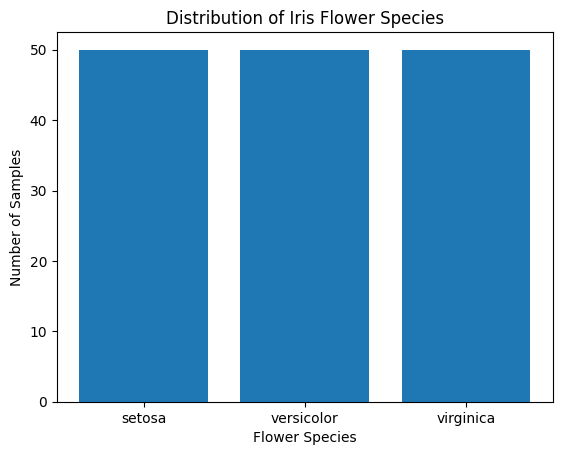

In [3]:

import matplotlib.pyplot as plt

# Count the samples for each species
species_counts = df["species"].value_counts().sort_index()

# Create a bar chart
plt.bar(iris.target_names, species_counts)

plt.title("Distribution of Iris Flower Species")
plt.xlabel("Flower Species")
plt.ylabel("Number of Samples")
plt.show()


In [4]:

from sklearn.model_selection import train_test_split

# Input features
X = iris.data

# Target labels
y = iris.target

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


Training samples: 120
Testing samples: 30


In [5]:

from sklearn.neighbors import KNeighborsClassifier

# Create the machine learning model
model = KNeighborsClassifier(n_neighbors=3)

# Train the model
model.fit(X_train, y_train)

print("Model training completed successfully!")


Model training completed successfully!


In [6]:

from sklearn.metrics import accuracy_score, classification_report

# Predict flower species for test data
y_pred = model.predict(X_test)

# Calculate model accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=iris.target_names))


Model Accuracy: 100.0 %

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00        10
   virginica       1.00      1.00      1.00        10

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



In [7]:

# Sepal length, Sepal width, Petal length, Petal width
sample_flower = [[5.1, 3.5, 1.4, 0.2]]

# Predict the flower species
prediction = model.predict(sample_flower)

# Display the predicted species
predicted_species = iris.target_names[prediction[0]]

print("Predicted Flower Species:", predicted_species)


Predicted Flower Species: setosa
